# Practical tasks

##### Please explore the datasets and answer the questions below.
##### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

In [236]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import seaborn as sns
from sklearn.cluster import KMeans
# you will need to import more libraries as needed

# Clustering tasks

The problem that we are going to solve in this section is to segment customers into different groups based on their shopping trends.

The dataset for this problem `shopping-data.csv`

#### 1. Load the data and preview

In [237]:
customer_data = pd.read_csv('shopping-data.csv')

In [238]:
customer_data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [239]:
customer_data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


#### 2. Plot scatter plot for annual income and spending score which will be used for clustering in the next steps

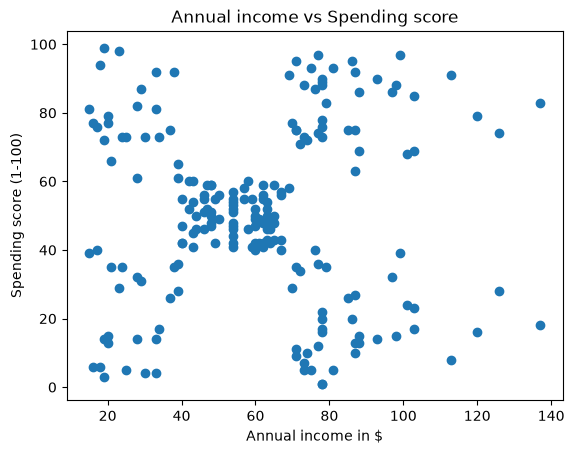

In [240]:
plt.scatter(customer_data['Annual Income (k$)'],customer_data['Spending Score (1-100)'])
plt.xlabel("Annual income in $")
plt.ylabel("Spending score (1-100)")
plt.title("Annual income vs Spending score")
plt.show()

#### 3. Normalize the data

In [241]:
# creating a new data set with customer data for analysis.
customer_data_new = customer_data[['Annual Income (k$)','Spending Score (1-100)']]

customer_data_new

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40
...,...,...
195,120,79
196,126,28
197,126,74
198,137,18


In [242]:
# Now normalising the values using standard Scalar.

scalar = StandardScaler()

customer_data_scaled = scalar.fit_transform(customer_data_new)

customer_data_scaled

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002],
       [-1.58632148, -1.4053405 ],
       [-1.58632148,  1.89449216],
       [-1.54815205, -1.36651894],
       [-1.54815205,  1.04041783],
       [-1.54815205, -1.44416206],
       [-1.54815205,  1.11806095],
       [-1.50998262, -0.59008772],
       [-1.50998262,  0.61338066],
       [-1.43364376, -0.82301709],
       [-1.43364376,  1.8556706 ],
       [-1.39547433, -0.59008772],
       [-1.39547433,  0.88513158],
       [-1.3573049 , -1.75473454],
       [-1.3573049 ,  0.88513158],
       [-1.24279661, -1.4053405 ],
       [-1.24279661,  1.23452563],
       [-1.24279661, -0.7065524 ],
       [-1.24279661,  0.41927286],
       [-1.20462718,

#### 4. Use Elbow method to decide number of clusters

In [243]:
elbow=[]
for i in range(2, 20):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=101, max_iter=200)
    kmeans.fit(customer_data_scaled)
    elbow.append(kmeans.inertia_)

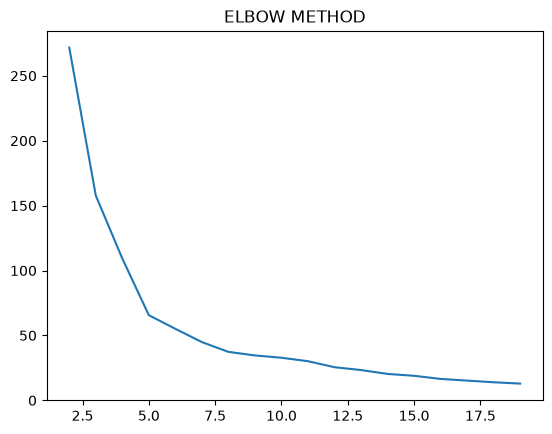

In [244]:
plt.plot(range(2, 20), elbow)
plt.title('ELBOW METHOD')
plt.show()

While seeing the graph it seems to that there is good curve at 5 so I take 5 as optimal cluster

#### 5. Perform Clustering using KMeans

In [245]:
cluster = KMeans(n_clusters=5,random_state=101, max_iter=200)
cluster.fit(customer_data_scaled)
y_pred = cluster.predict(customer_data_scaled)

#### 6. Plot scatter plot and color code in clustered groups

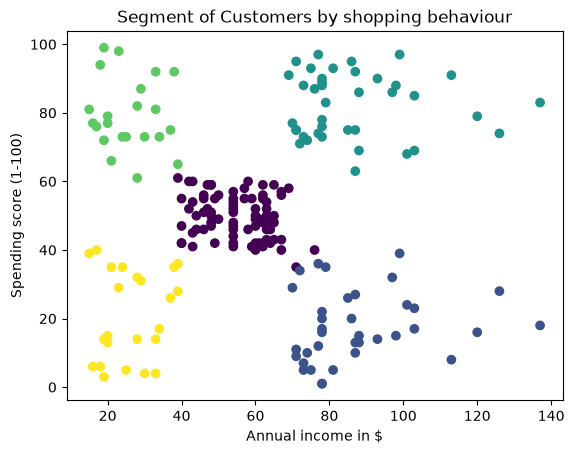

In [246]:
plt.scatter(customer_data['Annual Income (k$)'],customer_data['Spending Score (1-100)'], c=y_pred)
plt.xlabel("Annual income in $")
plt.ylabel("Spending score (1-100)")
plt.title("Segment of Customers by shopping behaviour")
plt.show()

#### 7. Plot dendrogram to decide number of clusters for Hierarchical Clustering. <br> Explain (free text in a markdown cell) what is the optimal number of clusters and why

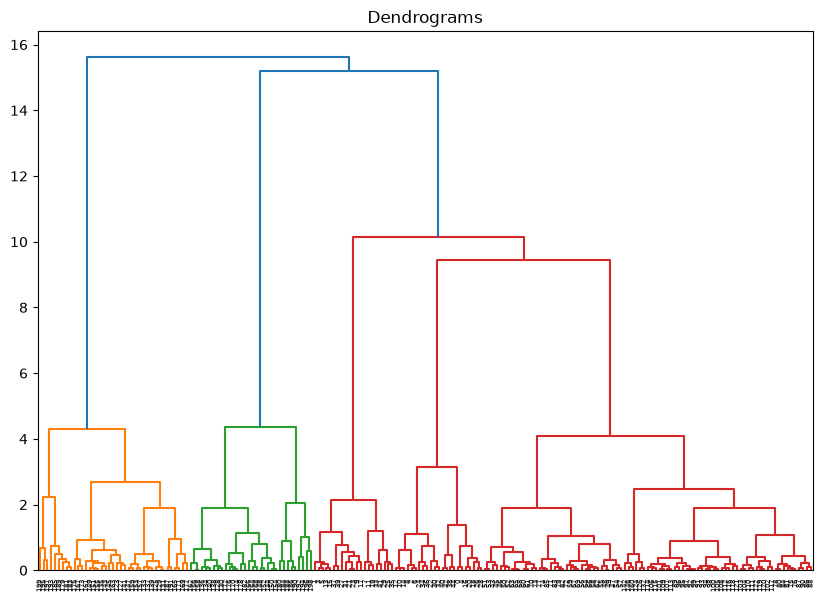

In [247]:
import scipy.cluster.hierarchy as shc
plt.figure(figsize=(10, 7))  
plt.title("Dendrograms")  
dend = shc.dendrogram(shc.linkage(customer_data_scaled, method='ward'))
plt.show()

I am choosing 5 as the optimal clsuter here since I were able to see the gap of the line from 4 - around 9 seems to the longest , So, i will be choosing that and I were able that there are total of 5 clusters under it therefore I have choosen 5, larger the line means the cluster are well seperated that's why i have choosen that.

#### 8. Do clustering using Hierarchical Clustering

In [248]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(customer_data_scaled)

#### 9. Plot scatter plot and color code in clustered groups

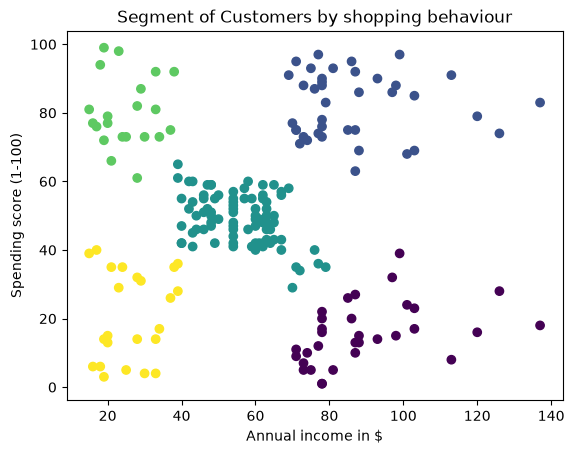

In [249]:
plt.scatter(customer_data['Annual Income (k$)'],customer_data['Spending Score (1-100)'], c=y_hc)
plt.xlabel("Annual income in $")
plt.ylabel("Spending score (1-100)")
plt.title("Segment of Customers by shopping behaviour")
plt.show()

####  10. Do KMeans and DBSCAN clustering on this data

In [250]:
from sklearn.datasets import make_moons
#moons_X: Data, moon_y: Labels
moons_X, moon_y = make_moons(n_samples=2000)

Text(0.5, 1.0, 'Half Moons')

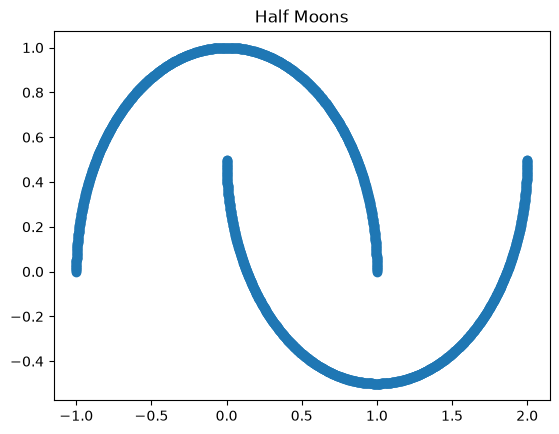

In [251]:
plt.scatter(moons_X[:,0],moons_X[:,1])
plt.title('Half Moons')

#### Using KMeans (do clustering and plot results (each cluster in own color))

In [252]:
# its clear that there are 2 cluster in this so I am doing K means using two clsuters.
kmeans = KMeans(n_clusters=2,random_state=101, max_iter=200)
kmeans.fit(moons_X)
y_pred = kmeans.predict(moons_X)


Text(0.5, 1.0, 'Segments of Half Moons')

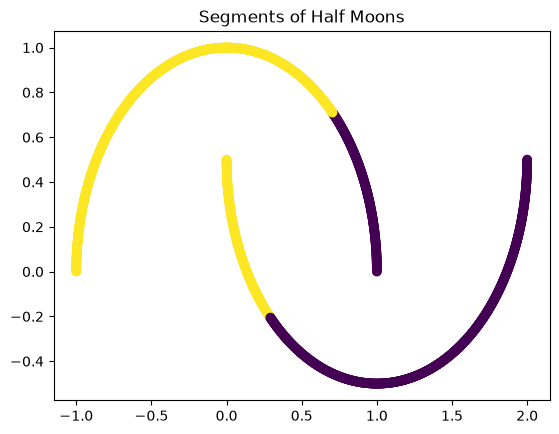

In [253]:
plt.scatter(moons_X[:,0],moons_X[:,1], c=y_pred)
plt.title('Segments of Half Moons')

In [254]:
from sklearn.metrics import accuracy_score

print(f"Accuracy: {accuracy_score(moon_y,y_pred)}")

Accuracy: 0.2485


Seems like that the K means is not clustering properly for this data set I can see only 0.75 as accuracy also from the grap its clearly visble when we see the colour of the clusters so it was kind ofa mix

#### 11. Using DBSCAN do clustering and plot results (each cluster in own color). Find the most suitable eps and minimal samples number

In [255]:
from sklearn.cluster import DBSCAN
# define the model
model = DBSCAN(eps=0.5, min_samples=3)
# fit model and predict clusters
yhat = model.fit_predict(moons_X)
# retrieve unique clusters
clusters = np.unique(yhat)
clusters

array([0, 1])

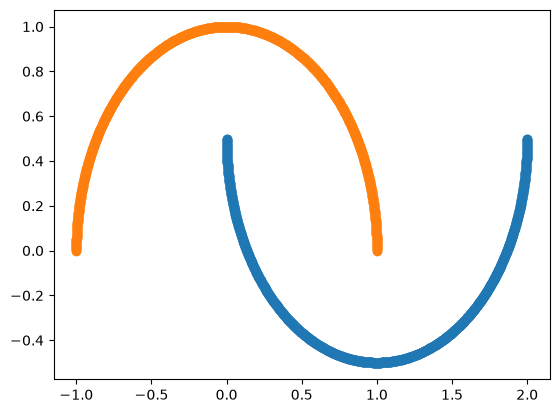

In [256]:
# create scatter plot for samples from each cluster
for cluster in clusters:
    # get row indexes for samples with this cluster
    row_ix = np.where(yhat == cluster)
    # create scatter of these samples
    plt.scatter(moons_X[row_ix, 0], moons_X[row_ix, 1])
    
# show the plot
plt.show()

In [257]:
print(f"accuracy_score: {accuracy_score(moon_y,yhat)}")

accuracy_score: 0.0


For the EPS first I have tried with 2 and i have not clustered anything therefore then I reduced the distance to 1 the result is same and then I reduced to 0.5 I were able to get 2 clusters as prefered.

#### 12. Compare the results of K-means and DBSCAN clustering
Explain why one or another is prefferable for such dataset, and differences if any.

I were able to see that DBSCAN is prefered for this kind of data K means were able to seperate the clusters but not correctly the accuracy was just 0.75 but here the DB scan due to that if were able to clasify the data with densisty since the data as well too dense and were able to see that each cluster visibly it clustered the data properly with eps 0.5 and with accuracy score of 100

### Perform PCA on penguins :)
###### This section uses kaggle dataset (https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species/data)
###### The tasks below include data analysis, data preprocessing, PCA, and application of classification to predict the target

#### 13. Describe the data. Do any additional exporations as you feel

In [258]:
# Dataset
penguins = pd.read_csv('penguins.csv')
penguins.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [259]:
# decribe the data, its size
print(penguins.shape)
penguins.info()

(344, 5)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


By checking the info it seems to be that there are some nulls on each cloumn to be cleaned.

In [260]:
penguins.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


<Axes: xlabel='flipper_length_mm', ylabel='Count'>

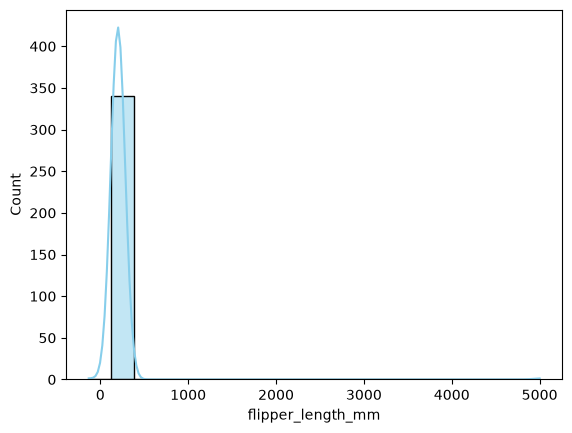

In [261]:
sns.histplot(penguins['flipper_length_mm'], kde=True, bins=20, color='skyblue')

In [262]:
penguins[penguins["flipper_length_mm"].between(500, 6000)]

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
9,42.0,20.2,5000.0,4250.0,MALE


#### Based on dataframe describe, in own words explain any abnormal characteristics 

Based on the dscribe I were able to see there were anomolies in flipper leanth the min value is -132 and max is 5000 considering this the length cannot be negative so it should be start from 0 and when checking the 75% We can see there is around 250 mm but we have max value of 5000 mm so we ploted it on a histagrom and found that most values lie between 0 and 500 therefore I will be removing the values that were greater that 500 

#### 14. Explore corrupted data

In [263]:
# find missing values. print entries with missing values, provide shape
print(penguins.isna().sum())

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64


In [264]:
# Entries with missing values
penguins[penguins.isna().any(axis=1)]

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
339,NaN,NaN,NaN,NaN,NaN


In [265]:
# Examine sex column
# for catagorical data its always best to check if the data only contains the values which are applicable
penguins['sex'].value_counts(dropna=False)

sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64

Found one annomoly in the sex column and the value is .

In [266]:
# find any unusual values. Print anomal rows
penguins[penguins['sex'] == '.']

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
336,44.5,15.7,217.0,4875.0,.


Based on the overall observation that the sex column contains more nulls and there are two rows where the entire row is empty and having one anomoly in sex column with . and having some outliers on on fliper length so that should be in the range of 0-500

#### 15. Based on observations above, prepare the data for PCA. Only valid rows should be present. <br> Preview dataframe, show its size

In [267]:
# clean
penguins_valid = penguins[penguins['sex'].isin(['MALE', 'FEMALE'])]
penguins_valid = penguins_valid[penguins_valid["flipper_length_mm"].between(0,500)]

print(penguins_valid.shape)
penguins_valid.head()


(332, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [268]:
penguins_valid.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,332.000000,332.000000,332.000000,332.000000
mean,44.021084,17.153012,200.975904,4206.475904
std,5.452462,1.960275,14.035971,806.361278
min,32.100000,13.100000,172.000000,2700.000000
25%,39.500000,15.600000,190.000000,3550.000000
50%,44.700000,17.300000,197.000000,4025.000000
75%,48.625000,18.700000,213.000000,4781.250000
max,59.600000,21.500000,231.000000,6300.000000


In [269]:
# scale numerical columns. assign to a variable X_penguins
X = penguins_valid.drop(columns="sex")

scalar = StandardScaler()

X_penguins = scalar.fit_transform(X)

X_penguins


array([[-0.90390586,  0.79035987, -1.42534179, -0.56694801],
       [-0.83043377,  0.12618674, -1.0685765 , -0.50484747],
       [-0.68348959,  0.43272819, -0.42639899, -1.18795343],
       ...,
       [ 1.17168063, -0.74234736,  1.50013355,  1.91707363],
       [ 0.21654349, -1.20215952,  0.78660298,  1.23396768],
       [ 1.07984052, -0.53798639,  0.85795603,  1.48236985]],
      shape=(332, 4))

In [270]:
# assign categorical column to a variable y_penguins
y_penguins = penguins_valid['sex']
y_penguins

0        MALE
1      FEMALE
2      FEMALE
4      FEMALE
5        MALE
        ...  
338    FEMALE
340    FEMALE
341      MALE
342    FEMALE
343      MALE
Name: sex, Length: 332, dtype: str

#### 15. Explain the chosen null values handling strategy, how it affects the dataset (pros/cons)

I have figured out that the most nulls values that are in the sex column and that is our target valuable It make sense if there is a value in target varable and there is no feature we can do some replacements with handling null here I removed it entirely the rows since the handling null could be not possible in the sitution and not making any sense. it reduced the data set size however still we have a good distribution of male and female entities that is almost 169 and 165 so that the removing of the null rows wont affect much. also comparing to the total of 344 we just removed a few like 9 nulls and 3 anomolies so will be no issues.

#### 16. Perform PCA with 2 components. Plot the results 

In [271]:
# Apply PCA to reduce to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_penguins)

print(f"Shape after PCA: {X_pca.shape}")
print(f"\nExplained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {pca.explained_variance_ratio_.sum():.2%}")

Shape after PCA: (332, 2)

Explained variance ratio: [0.68713344 0.19641564]
Total variance explained: 88.35%


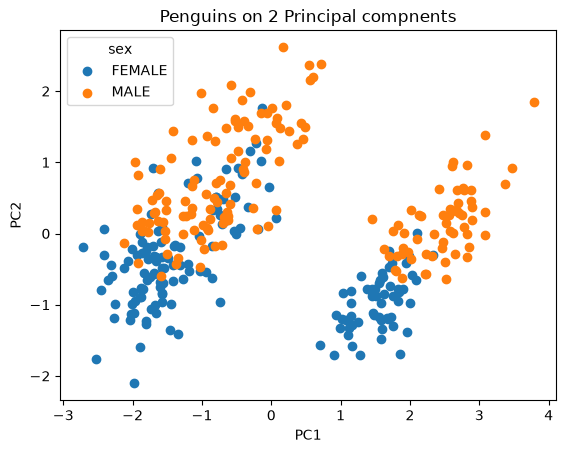

In [272]:
# Create a scatter plot
for i, sex in enumerate(["FEMALE","MALE"]):
    mask = y_penguins == sex
    plt.scatter(X_pca[mask,0],X_pca[mask,1],label=sex)

plt.title("Penguins on 2 Principal compnents")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title = "sex")
plt.show()

#### 17. Display scree plots to determine the optimal number of components and cumulative explained variance

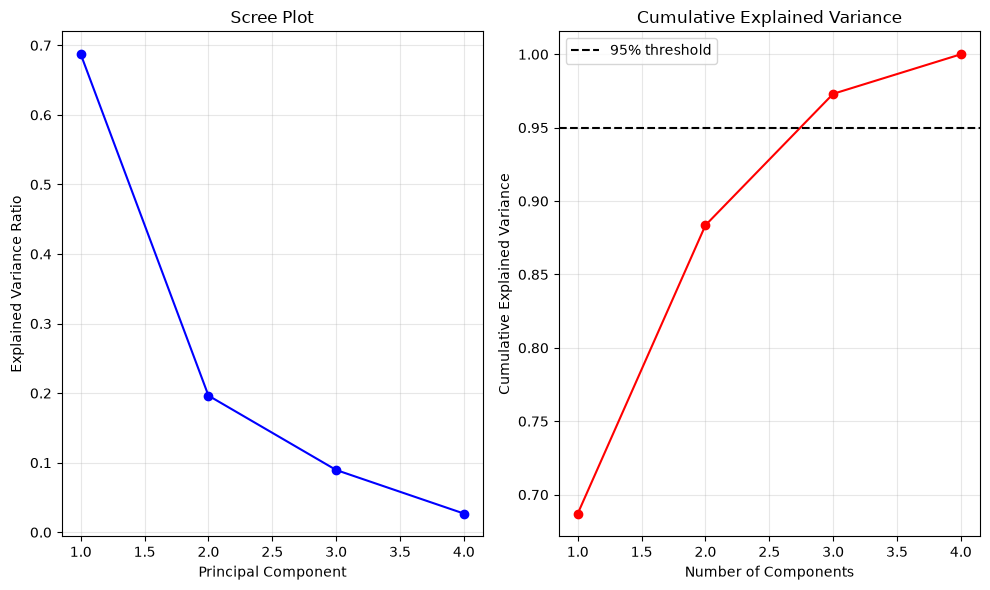

Explained variance by each component:
PC1: 68.71%
PC2: 19.64%
PC3: 8.95%
PC4: 2.69%


In [273]:
# Apply PCA with all components
pca_full = PCA()
pca_full.fit(X_penguins)

# Plot cumulative explained variance
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1), 
         pca_full.explained_variance_ratio_, 'bo-')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1),
         np.cumsum(pca_full.explained_variance_ratio_), 'ro-')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.axhline(y=0.95, color='k', linestyle='--', label='95% threshold')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Explained variance by each component:")
for i, var in enumerate(pca_full.explained_variance_ratio_):
    print(f"PC{i+1}: {var:.2%}")

#### 18. Calculate (show in numbers) and display component loadings

In [274]:
# Component loadings (how much each original feature contributes to each PC)
loadings = pd.DataFrame(
    pca_full.components_.T, 
    index=penguins_valid.select_dtypes(include='number').columns, 
    columns=["PC1","PC2","PC3","PC4"])
loadings

,PC1,PC2,PC3,PC4
culmen_length_mm,0.453174,0.604990,0.637706,-0.148160
culmen_depth_mm,-0.398518,0.792959,-0.431414,0.162115
flipper_length_mm,0.576880,0.003798,-0.231564,0.783309
body_mass_g,0.550478,0.072032,-0.594635,-0.581544


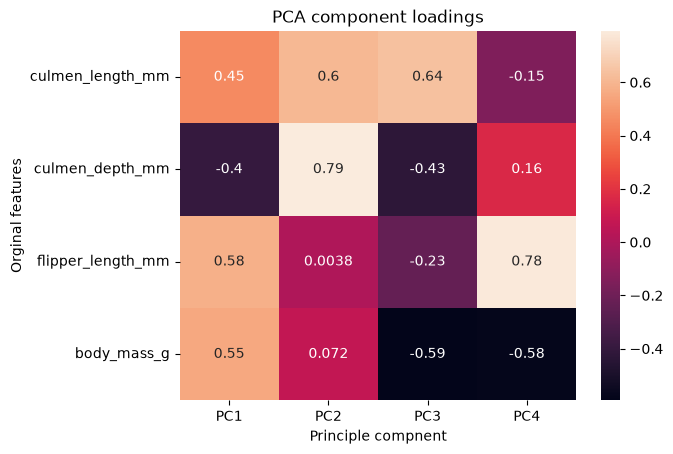

In [275]:
# show heatmap
sns.heatmap(loadings, annot = True)
plt.title("PCA component loadings")
plt.xlabel("Principle compnent")
plt.ylabel("Orginal features")
plt.show()

#### 19. Perform logistic regression (or any other classification algorithm) and evaluate the model

In [276]:
# import necessary libraries for model training and evaluation
# Use the PCA-transformed data (X_penguins_pca) and true labels (y_penguins)
# Train and evaluate a model
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_pca,y_penguins,test_size=0.20, random_state=101)


print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print(y_train.unique())

(265, 2) (67, 2) (265,) (67,)
<StringArray>
['FEMALE', 'MALE']
Length: 2, dtype: str


In [277]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(random_state=101)
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

In [278]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"F1 Score: {f1_score(y_test, y_pred, pos_label='MALE')}")

Accuracy: 0.7611940298507462
F1 Score: 0.7714285714285715


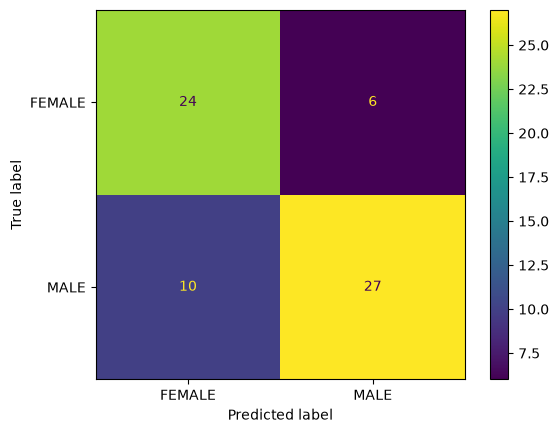

In [279]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)

#### 20. Train the model on all data points, and determine penguin sex for the data, where it was not originally identified

In [280]:
# 1. take entries from original data with sex unknown, scale numerical columns
penguins_sex_unknown = penguins[~penguins["sex"].isin(["MALE","FEMALE"])]

penguins_sex_unknown = penguins_sex_unknown.dropna(how='all')
penguins_sex_unknown



,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
336,44.5,15.7,217.0,4875.0,.


In [281]:

X_unknown = penguins_sex_unknown.drop(columns="sex")
X_unknown_scaled = scalar.fit_transform(X_unknown)

In [282]:
# 2. apply the same PCA transformation to the new data

X_unknown_pca = pca.fit_transform(X_unknown_scaled)


In [283]:
# 3. Train the model
# Define X_train and y_train using all PCA data from valid data
X_train, y_train = X_pca, y_penguins

final_model = LogisticRegression(random_state=101)
final_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",101
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following 

In [284]:
# 4. Make predictions on the new data. Display the features and predicted values
prediction = final_model.predict(X_unknown_pca)

penguins_sex_unknown['sex']=prediction

penguins_sex_unknown

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
8,34.1,18.1,193.0,3475.0,MALE
10,37.8,17.1,186.0,3300.0,MALE
11,37.8,17.3,180.0,3700.0,MALE
47,37.5,18.9,179.0,2975.0,MALE
246,44.5,14.3,216.0,4100.0,FEMALE
286,46.2,14.4,214.0,4650.0,FEMALE
324,47.3,13.8,216.0,4725.0,FEMALE
336,44.5,15.7,217.0,4875.0,MALE
